# 新製品の販売はいつピークを迎えるか：バスモデルによる普及予測

## 概要

発売後の販売が増えていても、その伸びがいつまで続くかはわからない。本記事は、[『マーケティングサイエンスの理論と実践』](https://gihyo.jp/book/2026/978-4-297-16025-8)の第3章「新製品の普及を予測する」の紹介である。バスモデルの考え方、数式、Pythonによる推定と予測を、章と同じ順に扱う。販売のピークと潜在市場規模を、生産・在庫・販促の検討材料として読む。

### 実行環境

カーネルは`wa-src(3.14.6)`、Pythonは3.14.6である。NumPy、SciPy、Polars、Matplotlib、IPythonを使う。上から順に実行すれば、模擬データの生成からグラフの保存まで再現できる。画像は`03_nb_files/`へSVG形式で保存し、ノートブックにも埋め込む。数値の表示は有効数字3桁とし、計算途中では丸めない。

In [1]:
from pathlib import Path
from pprint import pprint
from importlib.metadata import version
from io import BytesIO
from base64 import b64encode
import platform

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter, MaxNLocator, ScalarFormatter
from scipy.optimize import curve_fit
from scipy.special import expit, logit
from IPython.display import Latex, display

# リポジトリ直下と、ノートブックを置いた場所のどちらからでも実行できる。
BASE = Path.cwd()
if (BASE / "blog/03/03_nb.ipynb").exists():
    BASE = BASE / "blog/03"
FIG_DIR = BASE / "03_nb_files"
FIG_DIR.mkdir(exist_ok=True)


def sig3(value):
    """末尾のゼロを残し、有効数字3桁で表示する。"""
    return format(float(value), "#.3g").removesuffix(".")


def show_math(tex):
    # 重要式は \( ... \) で記述し、出力時は $$ ... $$ に変換する。
    # Markdownによるバックスラッシュの消失と、区切りの二重化を防ぐ。
    tex = tex.strip()
    if tex.startswith(r"\(") and tex.endswith(r"\)"):
        tex = tex[2:-2].strip()
    display(Latex("$$\n" + tex + "\n$$"))


def save_svg(fig, name):
    """SVGを保存し、閲覧環境に応じた画像を出力欄へ埋め込む。"""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if isinstance(axis.get_major_formatter(), ScalarFormatter):
                axis.set_major_formatter(FuncFormatter(
                    lambda value, _: str(int(value))
                    if float(value).is_integer() else sig3(value)
                ))
    path = FIG_DIR / name
    fig.savefig(path, format="svg", bbox_inches="tight", facecolor="white")
    # PNGはSVGを扱えないビューアー用。ファイルにはSVGだけを保存する。
    preview = BytesIO()
    fig.savefig(preview, format="png", dpi=120, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    width = min(960, int(fig.get_figwidth() * 96))
    display({"image/svg+xml": path.read_text(encoding="utf-8"),
             "image/png": b64encode(preview.getvalue()).decode("ascii")}, raw=True,
            metadata={"image/svg+xml": {"width": width},
                      "image/png": {"width": width}})


np.set_printoptions(formatter={"float_kind": sig3})
pl.Config.set_tbl_rows(8)
fonts = {font.name for font in font_manager.fontManager.ttflist}
for candidate in ("Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "Yu Gothic"):
    if candidate in fonts:
        plt.rcParams["font.family"] = candidate
        break
else:
    raise RuntimeError("日本語フォント（Noto Sans CJK JP等）が必要である。")
plt.rcParams.update({"font.size": 11, "axes.unicode_minus": False,
                     "svg.fonttype": "path", "svg.hashsalt": "blog03",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN = "#28658B", "#CE791E", "#368572"

print("仮想環境：wa-src(3.14.6)")
print(f"Python：{platform.python_version()}")
for package in ("numpy", "scipy", "polars", "matplotlib", "ipython"):
    print(f"{package}：{version(package)}")

仮想環境：wa-src(3.14.6)
Python：3.14.6
numpy：2.4.6
scipy：1.18.1
polars：2.1.0
matplotlib：3.11.2
ipython：9.18.1


## 1. 発売初期の販売だけで、先を見通せるか

新製品には過去の販売実績がなく、類似製品の数字も価格や競合条件が異なる。発売後も、初期の購入者とその後の購入者では購入のきっかけが違う場合がある。本章は、この違いを踏まえて普及の過程をモデル化する。

私は、販売が増えた月の数字をそのまま先へ延ばすより、増加が止まる条件を確認したい。バスモデルでは、まだ購入していない人が減ると、販売の伸びも鈍くなると考える。

## 2. 外部情報と、採用者からの影響を分ける

モデルの対象は初回の採用である。ここでは耐久財を想定し、1人が初回に1台を購入する。買い替えやリピート購入は含めない。

潜在市場規模を$M$、累積採用者数を$N(t)$とすると、未採用者は$M-N(t)$人である。外部情報による項は$p(M-N)$、採用者からの影響による項は$q(N/M)(M-N)$となる。両者を足し、共通する未採用者数でくくる。

In [2]:
show_math(r"""\(
\begin{aligned}
n(t)&=p\{M-N(t)\}+q\frac{N(t)}{M}\{M-N(t)\}\\
&=\left(p+q\frac{N(t)}{M}\right)\{M-N(t)\},\\
N(0)=0&\ \Longrightarrow\ n(0)=pM,\\
N(t)=M&\ \Longrightarrow\ n(t)=(p+q)\times0=0.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

$p$は採用者数に依存しない部分、$q$は普及率に応じて増える部分の係数である。人を固定した2種類に分類する式ではない。また、販売データから得た$p$と$q$を、広告と口コミの因果効果と読み替えることもできない。

連続時間では$p+qN/M$は瞬間的な採用率であり、確率そのものではない。係数は時間の単位に依存する。$q>p$なら発売後に販売のピークが生じる。その理由を式から確認する。

### 累積採用者数の式を求める

$F=N/M$を普及率とする。$n=dN/dt$なので、基本式を$M$で割り、$F$を左辺へ集める。分数を分解してから、初期条件$F(0)=0$を使って積分する。$u$は積分用の変数である。

In [3]:
show_math(r"""\(
\begin{aligned}
\frac{dF}{dt}&=(p+qF)(1-F),\\
\frac{1}{(p+qF)(1-F)}
&=\frac{1}{p+q}\left(\frac{q}{p+qF}+\frac{1}{1-F}\right),\\
\int_0^{F(t)}\left(\frac{q}{p+qu}+\frac{1}{1-u}\right)du
&=(p+q)\int_0^t ds,\\
\left[\log(p+qu)-\log(1-u)\right]_0^{F(t)}&=(p+q)t,\\
\log\frac{p+qF}{p(1-F)}&=(p+q)t.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

対数を外して$F$の項をまとめる。分子と分母に$e^{-(p+q)t}/p$を掛ければ、累積採用者数の式となる。$t=0$では0、時間が十分に経つと$M$に近づく。

In [4]:
show_math(r"""\(
\begin{aligned}
p+qF&=p(1-F)e^{(p+q)t},\\
qF+pFe^{(p+q)t}&=p\{e^{(p+q)t}-1\},\\
F&=\frac{p\{e^{(p+q)t}-1\}}{q+pe^{(p+q)t}}
=\frac{1-e^{-(p+q)t}}{1+(q/p)e^{-(p+q)t}},\\
N(t)&=MF(t)=M\frac{1-e^{-(p+q)t}}{1+(q/p)e^{-(p+q)t}}.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

### 新規採用の速度とピークを求める

$a=p+q$、$b=q/p$、$z=e^{-at}$と置くと$dz/dt=-az$である。商の微分で$n(t)$を求め、さらに微分して最大になる時点を調べる。以下では$p>0$、$q>0$とする。

In [5]:
show_math(r"""\(
\begin{aligned}
n(t)&=\frac{d}{dt}\left\{M\frac{1-z}{1+bz}\right\}\\
&=M\frac{az(1+bz)-(1-z)(-abz)}{(1+bz)^2}\\
&=Ma\frac{z\{1+bz+b(1-z)\}}{(1+bz)^2}\\
&=\frac{M(p+q)^2}{p}\frac{z}{(1+bz)^2}
=C\frac{z}{(1+bz)^2},\qquad C=\frac{M(p+q)^2}{p},\\
\frac{dn}{dt}
&=C\left\{\frac{z'}{(1+bz)^2}-\frac{2bzz'}{(1+bz)^3}\right\}\\
&=Cz'\frac{1-bz}{(1+bz)^3}
=-aCz\frac{1-bz}{(1+bz)^3}.
\end{aligned}
\)""")

show_math(r"""\(
\begin{aligned}
\frac{dn}{dt}=0
&\ \Longrightarrow\ 1-bz=0
\ \Longrightarrow\ e^{-(p+q)t^*}=\frac{p}{q},\\
-(p+q)t^*&=\log(p/q),\\
t^*&=\frac{\log(q/p)}{p+q},\\
n(t^*)&=\frac{M(p+q)^2}{p}
\frac{p/q}{\{1+(q/p)(p/q)\}^2}
=\frac{M(p+q)^2}{4q}.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

$q>p$ならピーク前は$dn/dt>0$、ピーク後は$dn/dt<0$となり、累積採用者数はS字になる。$q\leq p$では発売時点が最大である。図1は2つの採用要因と累積採用者数、図2は$p$と$q$を別々に変えた例である。$q$を増やせば必ずピークが遅くなるわけではない。図の係数は形を確認するための設定であり、後の月次モデルから換算した値ではない。

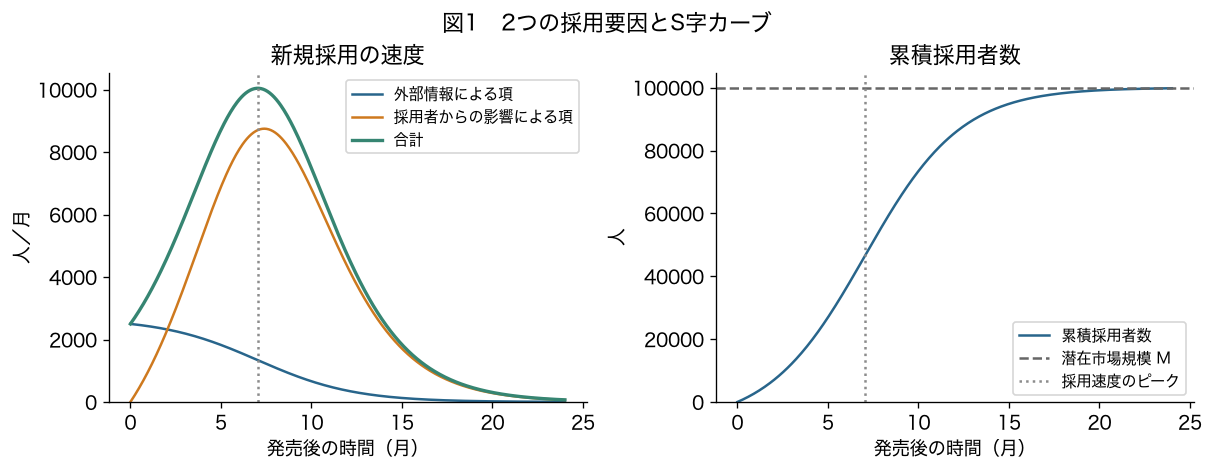

In [6]:
def continuous_bass(t, p, q, M):
    """連続時間版の累積採用者数を計算する。"""
    z = np.exp(-(p + q) * t)
    return M * (1 - z) / (1 + q / p * z)


t = np.linspace(0, 24, 400)
p_demo, q_demo, M_demo = 0.0250, 0.350, 100_000
N_demo = continuous_bass(t, p_demo, q_demo, M_demo)
external = p_demo * (M_demo - N_demo)
internal = q_demo * (N_demo / M_demo) * (M_demo - N_demo)
t_peak_demo = np.log(q_demo / p_demo) / (p_demo + q_demo)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.80), layout="constrained")
axes[0].plot(t, external, label="外部情報による項", color=BLUE)
axes[0].plot(t, internal, label="採用者からの影響による項", color=ORANGE)
axes[0].plot(t, external + internal, label="合計", color=GREEN, linewidth=2)
axes[0].axvline(t_peak_demo, color="0.55", linestyle=":")
axes[0].set(title="新規採用の速度", ylabel="人／月")
axes[0].legend(fontsize=9)
axes[1].plot(t, N_demo, color=BLUE, label="累積採用者数")
axes[1].axhline(M_demo, color="0.40", linestyle="--", label="潜在市場規模 M")
axes[1].axvline(t_peak_demo, color="0.55", linestyle=":", label="採用速度のピーク")
axes[1].set(title="累積採用者数", ylabel="人")
axes[1].legend(fontsize=9, loc="lower right")
for ax in axes:
    ax.set_xlabel("発売後の時間（月）")
    ax.set_ylim(bottom=0)
fig.suptitle("図1　2つの採用要因とS字カーブ")
save_svg(fig, "01_diffusion.svg")

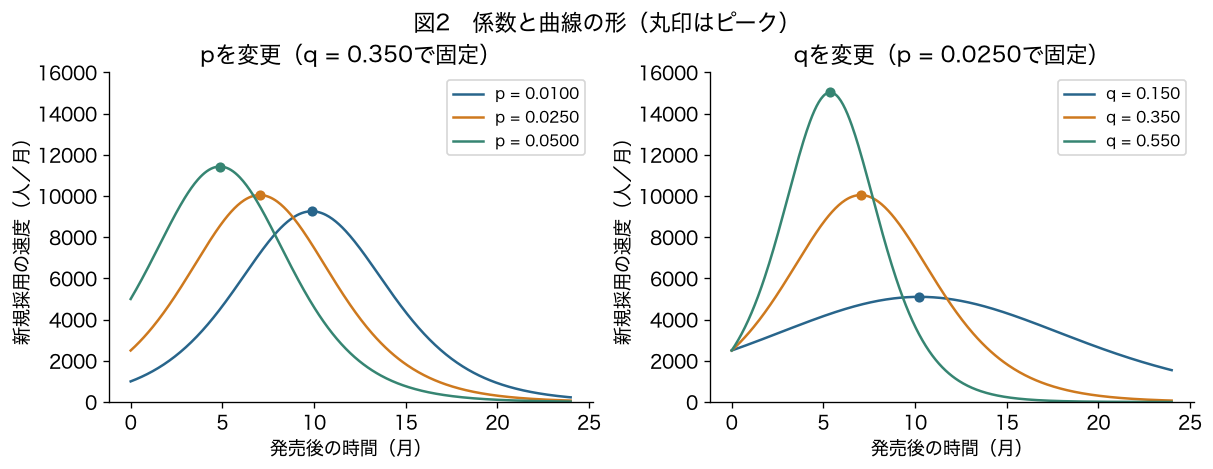

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.80), layout="constrained")
scenarios = [([0.0100, 0.0250, 0.0500], "p"),
             ([0.150, 0.350, 0.550], "q")]
for ax, (values, parameter) in zip(axes, scenarios):
    for value, color in zip(values, [BLUE, ORANGE, GREEN]):
        p = value if parameter == "p" else p_demo
        q = value if parameter == "q" else q_demo
        N = continuous_bass(t, p, q, M_demo)
        n = (p + q * N / M_demo) * (M_demo - N)
        ax.plot(t, n, label=f"{parameter} = {sig3(value)}", color=color)
        peak = np.log(q / p) / (p + q)
        peak_rate = M_demo * (p + q) ** 2 / (4 * q)
        ax.scatter([peak], [peak_rate], color=color, s=26)
    fixed = "q = 0.350" if parameter == "p" else "p = 0.0250"
    ax.set(title=f"{parameter}を変更（{fixed}で固定）",
           xlabel="発売後の時間（月）", ylabel="新規採用の速度（人／月）", ylim=(0, 16_000))
    ax.legend(fontsize=9)
fig.suptitle("図2　係数と曲線の形（丸印はピーク）")
save_svg(fig, "02_parameters.svg")

### 月次データには離散時間版を使う

月次の販売台数$n_t$は、瞬間的な速度$n(t)$とは異なる。本章の実装では、前月末の累積値$N_{t-1}$から1か月分を計算する。連続時間の解を正確に月単位へ変換した式ではない。推定と予測の両方で同じ離散時間版を使う。

$p>0$、$q>0$、$p+q<1$なら、括弧内の採用確率は0から1に収まる。$p=0.0250$、$q=0.350$、$M=100{,}000$として、最初の2か月を計算する。

In [8]:
show_math(r"""\(
\begin{aligned}
n_t&=\left(p+q\frac{N_{t-1}}{M}\right)(M-N_{t-1}),
\qquad N_t=N_{t-1}+n_t,\\
N_0&=0,\qquad n_1=0.0250\times100{,}000=2{,}500,\\
N_1&=0+2{,}500=2{,}500,\\
n_2&=\left(\frac{1}{40}+\frac{7}{20}\frac{2{,}500}{100{,}000}\right)
(100{,}000-2{,}500)\\
&=\left(\frac{1}{40}+\frac{7}{800}\right)97{,}500
=\frac{27}{800}\times97{,}500\\
&=\frac{2{,}632{,}500}{800}\approx3.29\times10^3.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

## 3. Pythonでデータを作り、モデルを推定する

### データの準備

必要な列は発売後の期と初回販売台数である。販売ゼロの月も残し、欠損と区別する。欠品、予約販売、価格変更なども記録しておく。

以下は実測データではない。先ほどの設定値で24か月分を生成し、各月の販売台数の10%を標準偏差とする正規誤差を加える。誤差は観測値だけに加え、次期の計算は誤差を含まない累積値から進める。最初の10か月を推定用、11〜24か月を検証用に分ける。

shape: (5, 3)
┌────────┬─────────┬───────┐
│ period ┆ n_sales ┆ N_cum │
│ ---    ┆ ---     ┆ ---   │
│ i64    ┆ i64     ┆ i64   │
╞════════╪═════════╪═══════╡
│ 1      ┆ 2576    ┆ 2576  │
│ 2      ┆ 2948    ┆ 5524  │
│ 3      ┆ 4584    ┆ 10108 │
│ 4      ┆ 5923    ┆ 16031 │
│ 5      ┆ 5384    ┆ 21415 │
└────────┴─────────┴───────┘


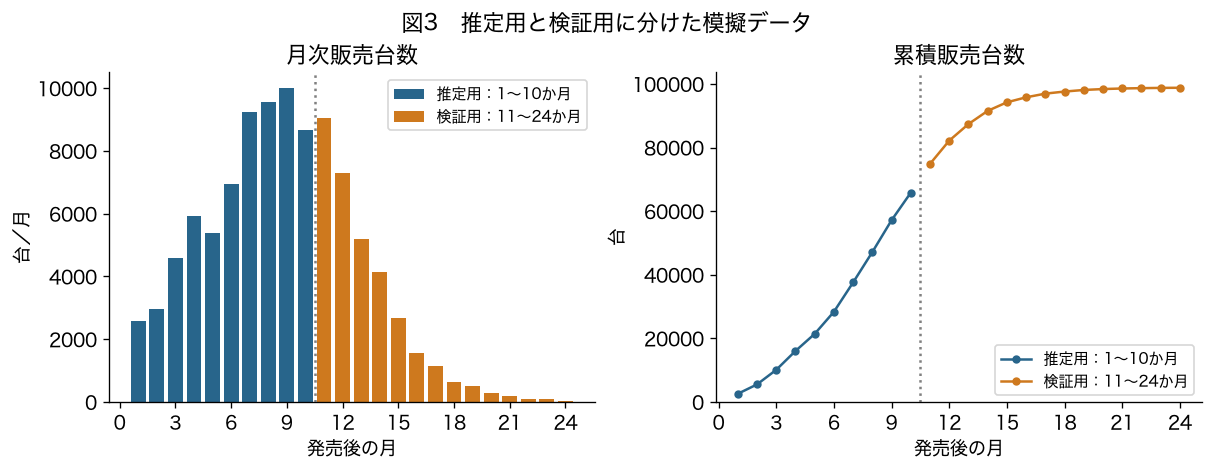

In [9]:
rng = np.random.default_rng(42)
p_true, q_true, M_true = 0.0250, 0.350, 100_000
N_latent = 0.00
sales = []
for _ in range(24):
    n_latent = (p_true + q_true * N_latent / M_true) * (M_true - N_latent)
    # 元の章と同じ生成方法。整数化の前に負の観測値を0へ切り上げる。
    sales.append(int(max(n_latent + rng.normal(0, 0.100 * n_latent), 0)))
    N_latent += n_latent

df = pl.DataFrame({"period": np.arange(1, 25), "n_sales": sales})
df = df.with_columns(pl.col("n_sales").cum_sum().alias("N_cum"))
df_observed, df_validation = df.head(10), df.slice(10)
print(df.head())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.80), layout="constrained")
for data, color, label in [(df_observed, BLUE, "推定用：1〜10か月"),
                           (df_validation, ORANGE, "検証用：11〜24か月")]:
    axes[0].bar(data["period"], data["n_sales"], color=color, label=label)
    axes[1].plot(data["period"], data["N_cum"], "o-", color=color, label=label, markersize=4)
axes[0].set(title="月次販売台数", ylabel="台／月")
axes[1].set(title="累積販売台数", ylabel="台")
for ax in axes:
    ax.axvline(10.5, color="0.50", linestyle=":")
    ax.set(xlabel="発売後の月", ylim=(0, None))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(fontsize=9)
fig.suptitle("図3　推定用と検証用に分けた模擬データ")
save_svg(fig, "03_sample.svg")

### 重み付き非線形最小二乗法

販売台数が多い月ほど誤差も大きいため、観測値$y_t$と予測値$\hat{n}_t$の差を誤差の標準偏差$\sigma_t$で割り、二乗して足す。まず等しい重みで推定し、予測値から重みを更新する。観測値を直接分母に使うと、小さく観測された月へ過大な重みが付き得る。

推定用のベクトルを$\mathbf{u}=(u_1,u_2,u_3)$とし、下の変換で係数の制約を守る。$M_{\min}$は推定期間の累積販売台数である。コードではこのベクトルを`theta`と呼ぶ。

In [10]:
show_math(r"""\(
\begin{aligned}
r_t&=y_t-\hat{n}_t,\qquad
Q=\sum_{t=1}^{T}\left(\frac{r_t}{\sigma_t}\right)^2
=\sum_{t=1}^{T}\frac{(y_t-\hat{n}_t)^2}{\sigma_t^2},\\
\sigma_t&\leftarrow\max(0.100\hat{n}_t,1),\\
s(x)&=\frac{1}{1+e^{-x}},\quad
p=s(u_1),\quad q=(1-p)s(u_2),\quad M=M_{\min}+e^{u_3},\\
p+q&=p+(1-p)s(u_2)<p+(1-p)=1,\qquad M>M_{\min}.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

In [11]:
def bass_model_sequence(
    n_periods: int, p: float, q: float, M: float, N_start: float = 0.00
) -> np.ndarray:
    """N_startからn_periods期分の新規採用者数を1期ずつ予測する。"""
    if not (p > 0 and q > 0 and p + q < 1 and M > 0):
        raise ValueError("p>0, q>0, p+q<1, M>0 が必要である。")
    if not (0 <= N_start < M):
        raise ValueError("N_start は0以上M未満である必要がある。")

    n_pred = np.zeros(n_periods, dtype=float)
    N_cum = float(N_start)
    for i in range(n_periods):
        adoption_prob = p + q * N_cum / M
        remaining = M - N_cum
        n_t = adoption_prob * remaining
        if not (0 <= adoption_prob <= 1 and -1.00e-08 <= n_t <= remaining + 1.00e-08):
            raise ValueError("採用確率が0以上1以下になる条件を満たしていない。")
        n_pred[i] = n_t
        N_cum += n_t
    return n_pred


def bass_model_predict(periods: np.ndarray, p: float, q: float, M: float) -> np.ndarray:
    """発売後第1期から連続する各期の予測値を返す。"""
    periods_raw = np.asarray(periods)
    if (
        periods_raw.ndim != 1
        or not np.all(np.isfinite(periods_raw))
        or not np.all(periods_raw == periods_raw.astype(int))
    ):
        raise ValueError("periods は有限な整数の1次元配列である必要がある。")
    periods = periods_raw.astype(int)
    expected = np.arange(1, len(periods) + 1)
    if not np.array_equal(periods, expected):
        raise ValueError("periods は1から欠番なく並べる必要がある。")
    return bass_model_sequence(len(periods), p, q, M)


def unpack_theta(theta: np.ndarray, M_floor: float):
    """制約のないthetaを p>0, q>0, p+q<1, M>M_floor へ変換する。"""
    p = expit(theta[0])
    q = (1.00 - p) * expit(theta[1])
    M = M_floor + np.exp(theta[2])
    return p, q, M


def pack_theta(p: float, q: float, M: float, M_floor: float) -> np.ndarray:
    """p, q, Mを最適化用のthetaへ変換する。"""
    p = np.clip(p, 1.00e-06, 1 - 1.00e-06)
    q_share = np.clip(q / (1 - p), 1.00e-06, 1 - 1.00e-06)
    M_excess = max(M - M_floor, 1.00)
    return np.array([logit(p), logit(q_share), np.log(M_excess)])

In [12]:
# 初期値を変えて推定し、重み付き残差平方和が最小の解を採用する。
# 最後のヤコビ行列は、変換後の共分散をp・q・Mの尺度へ戻すために使う。
def estimate_bass(
    periods: np.ndarray,
    n_sales_obs: np.ndarray,
    M_floor: float,
    initial_guesses: list[tuple],
):
    """複数の初期値と反復重み付けでp, q, Mを推定する。"""
    periods = np.asarray(periods, dtype=int)
    n_sales_obs = np.asarray(n_sales_obs, dtype=float)

    def transformed_model(x, theta_p, theta_q, theta_M):
        p, q, M = unpack_theta(np.array([theta_p, theta_q, theta_M]), M_floor)
        return bass_model_predict(x, p, q, M)

    theta_lower = [-12.0, -12.0, np.log(max(1.00, M_floor * 0.0100))]
    theta_upper = [6.00, 6.00, np.log(max(1.00e+06, M_floor * 100.))]
    candidates = []

    for initial in initial_guesses:
        theta = pack_theta(*initial, M_floor=M_floor)
        sigma = np.ones_like(n_sales_obs)
        try:
            for _ in range(8):
                theta_prev = theta.copy()
                theta, _ = curve_fit(
                    transformed_model,
                    periods,
                    n_sales_obs,
                    p0=theta,
                    bounds=(theta_lower, theta_upper),
                    sigma=sigma,
                    absolute_sigma=False,
                    x_scale=[3.00, 3.00, 10.0],
                    max_nfev=10_000,
                )
                n_fit = transformed_model(periods, *theta)
                sigma = np.maximum(0.100 * n_fit, 1.00)
                if np.max(np.abs(theta - theta_prev)) < 1.00e-07:
                    break

            theta, pcov_theta = curve_fit(
                transformed_model,
                periods,
                n_sales_obs,
                p0=theta,
                bounds=(theta_lower, theta_upper),
                sigma=sigma,
                absolute_sigma=False,
                x_scale=[3.00, 3.00, 10.0],
                max_nfev=10_000,
            )
            n_fit = transformed_model(periods, *theta)
            objective = np.sum(((n_sales_obs - n_fit) / sigma) ** 2)
            candidates.append((objective, theta, pcov_theta, sigma, n_fit))
        except (RuntimeError, ValueError):
            continue

    if not candidates:
        raise RuntimeError("すべての初期値で推定に失敗した。")

    objective, theta, pcov_theta, sigma, n_fit = min(
        candidates, key=lambda item: item[0]
    )
    p, q, M = unpack_theta(theta, M_floor)

    p_grad = p * (1 - p)
    q_share = expit(theta[1])
    transform_jac = np.array(
        [
            [p_grad, 0.00, 0.00],
            [-p_grad * q_share, (1 - p) * q_share * (1 - q_share), 0.00],
            [0.00, 0.00, M - M_floor],
        ]
    )
    pcov = transform_jac @ pcov_theta @ transform_jac.T
    perr = np.sqrt(np.maximum(np.diag(pcov), 0.00))

    return {
        "popt": np.array([p, q, M]),
        "perr": perr,
        "theta": theta,
        "pcov_theta": pcov_theta,
        "sigma": sigma,
        "n_fit": n_fit,
        "objective": objective,
    }

In [13]:
periods = df_observed["period"].to_numpy()
y = df_observed["n_sales"].to_numpy().astype(float)
M_floor = float(y.sum())
initial_guesses = [(0.0100, 0.200, M_floor * 1.50),
                   (0.0250, 0.350, M_floor * 2.00),
                   (0.0500, 0.500, M_floor * 4.00),
                   (0.100, 0.200, M_floor * 8.00)]
fit = estimate_bass(periods, y, M_floor, initial_guesses)
p_est, q_est, M_est = fit["popt"]
n_fit = fit["n_fit"]

# NumPyの結果を辞書にまとめ、pprintで表示する。
pprint({name: {"推定値": sig3(value), "標準誤差の概算": sig3(se), "設定値": sig3(truth)}
        for name, value, se, truth in zip(
            ["p", "q", "M"], fit["popt"], fit["perr"], [p_true, q_true, M_true])},
       sort_dicts=False)
pprint({"p + q": sig3(p_est + q_est),
        "採用確率の条件を満たす": bool(p_est > 0 and q_est > 0 and p_est + q_est < 1)})

{'p': {'推定値': '0.0255', '標準誤差の概算': '0.00247', '設定値': '0.0250'},
 'q': {'推定値': '0.334', '標準誤差の概算': '0.0366', '設定値': '0.350'},
 'M': {'推定値': '9.85e+04', '標準誤差の概算': '1.13e+04', '設定値': '1.00e+05'}}
{'p + q': '0.359', '採用確率の条件を満たす': True}


推定値は$\hat{p}=0.0255$、$\hat{q}=0.334$、$\hat{M}\approx9.85\times10^4$台となる。$M$の標準誤差の概算は$1.13\times10^4$台である。標準誤差は推定値付近の近似であり、将来の販売台数の範囲を示す値ではない。

図4では当てはまりと残差を確認する。$\bar{y}$を推定期間の平均とすると、決定係数は次の式になる。この例の$R^2$は0.954であるが、これは推定に使った期間の評価である。

<IPython.core.display.Latex object>

{'推定期間のR²': '0.954'}


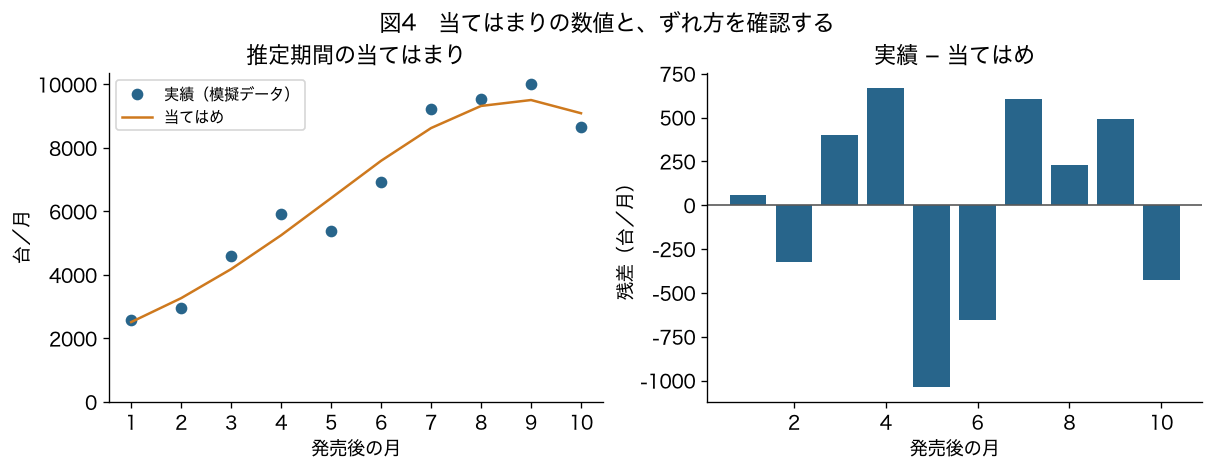

In [14]:
show_math(r"""\(
\begin{aligned}
\bar{y}&=\frac{1}{T}\sum_{t=1}^{T}y_t,\qquad
\mathrm{RSS}=\sum_{t=1}^{T}(y_t-\hat{n}_t)^2,\\
\mathrm{TSS}&=\sum_{t=1}^{T}(y_t-\bar{y})^2,\qquad
R^2=1-\frac{\mathrm{RSS}}{\mathrm{TSS}}.
\end{aligned}
\)""")
residuals = y - n_fit
r2 = 1 - np.sum(residuals ** 2) / np.sum((y - y.mean()) ** 2)
pprint({"推定期間のR²": sig3(r2)})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.80), layout="constrained")
axes[0].plot(periods, y, "o", color=BLUE, label="実績（模擬データ）")
axes[0].plot(periods, n_fit, color=ORANGE, label="当てはめ")
axes[0].set(title="推定期間の当てはまり", ylabel="台／月", ylim=(0, None))
axes[0].legend(fontsize=9)
axes[1].bar(periods, residuals, color=BLUE)
axes[1].axhline(0, color="0.35", linewidth=1)
axes[1].set(title="実績 − 当てはめ", ylabel="残差（台／月）")
for ax in axes:
    ax.set_xlabel("発売後の月")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle("図4　当てはまりの数値と、ずれ方を確認する")
save_svg(fig, "04_fit.svg")

## 4. 未使用の期間で予測を確認する

10か月時点の累積販売台数65,814台を出発点として、48か月目まで予測する。本章では、この観測された累積値を現在の状態として扱う。状態自体の測定誤差を推定する方法は含めない。11〜24か月の平均絶対誤差（MAE）は、月ごとの予測のずれの絶対値を平均したものである。

In [15]:
future_months = np.arange(11, 49)
observed_cum = float(y.sum())
n_future = bass_model_sequence(38, p_est, q_est, M_est, N_start=observed_cum)
N_future = observed_cum + np.cumsum(n_future)
validation_y = df_validation["n_sales"].to_numpy().astype(float)
validation_residuals = validation_y - n_future[:14]
mae = np.mean(np.abs(validation_residuals))

# 離散時間版の予測値からピーク月を求める。連続時間の式は流用しない。
all_predictions = np.concatenate([n_fit, n_future])
peak_month = int(np.argmax(all_predictions)) + 1
peak_sales = float(all_predictions[peak_month - 1])
pprint({"検証期間のMAE（台／月）": sig3(mae), "ピーク月": peak_month,
        "ピークの販売台数": sig3(peak_sales),
        "10か月時点の普及率（%）": sig3(100 * observed_cum / M_est)}, sort_dicts=False)
show_math(r"""\(
\mathrm{MAE}=\frac{1}{14}\sum_{t=11}^{24}|y_t-\hat{n}_t|
\)""")

{'検証期間のMAE（台／月）': '208',
 'ピーク月': 9,
 'ピークの販売台数': '9.51e+03',
 '10か月時点の普及率（%）': '66.8'}


<IPython.core.display.Latex object>

MAEは208台／月、ピークは9か月目の約$9.51\times10^3$台となる。予測を作る10か月時点ではピークは過去にあり、この結果を「将来のピークを事前に当てた例」とは扱わない。

次に、推定したモデルからデータを200回作り直し、毎回再推定する。これがパラメトリック・ブートストラップである。図5の帯は各月の予測曲線の10〜90百分位であり、中央80%の範囲を示す。将来の観測誤差や、価格変更・競合参入などの不確実性は含まない。

In [16]:
rng_boot = np.random.default_rng(123)
future_paths = []
for _ in range(200):
    # 推定期間の観測データだけを再生成する。
    y_boot = np.maximum(rng_boot.normal(n_fit, fit["sigma"]), 0.00)
    floor_boot = max(float(y_boot.sum()), observed_cum)
    start_M = max(M_est, floor_boot * 1.05)
    try:
        fit_boot = estimate_bass(
            periods, y_boot, floor_boot,
            [(p_est, q_est, start_M), (0.0250, 0.350, floor_boot * 2.00)],
        )
        # 全ての予測を、元データの10か月末の累積値から開始する。
        future_paths.append(bass_model_sequence(
            len(future_months), *fit_boot["popt"], N_start=observed_cum))
    except RuntimeError:
        continue

future_paths = np.asarray(future_paths)
if len(future_paths) < 100:
    raise RuntimeError("再推定の成功回数が不足している。")
lower, upper = np.quantile(future_paths, [0.100, 0.900], axis=0)
cum_paths = observed_cum + np.cumsum(future_paths, axis=1)
cum_lower, cum_upper = np.quantile(cum_paths, [0.100, 0.900], axis=0)
pprint({"再推定の成功回数": len(future_paths), "試行回数": 200})

{'再推定の成功回数': 200, '試行回数': 200}


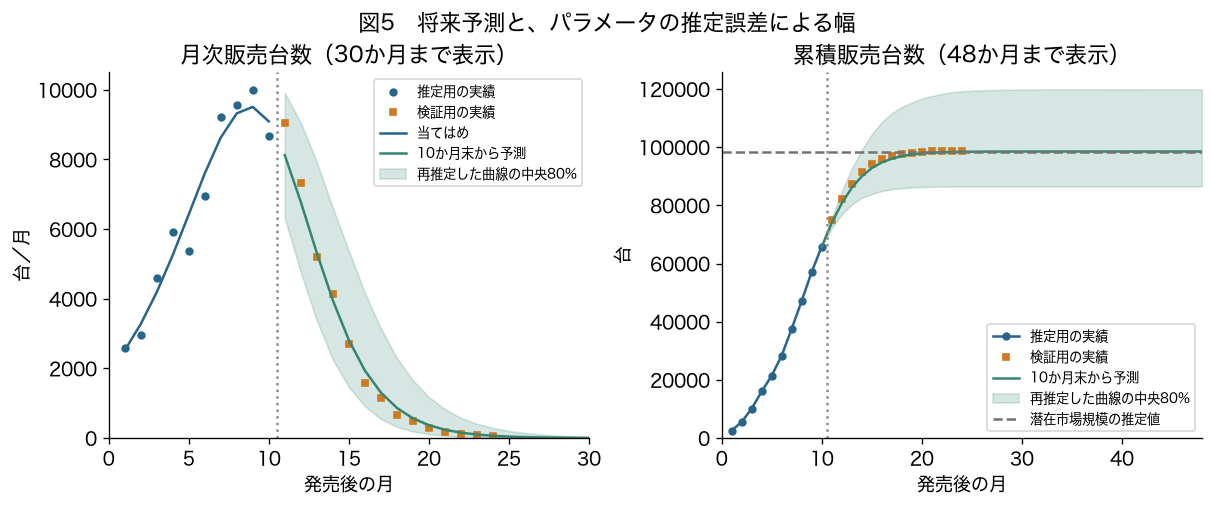

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.10), layout="constrained")
validation_months = df_validation["period"].to_numpy()
axes[0].plot(periods, y, "o", color=BLUE, label="推定用の実績", markersize=4)
axes[0].plot(validation_months, validation_y, "s", color=ORANGE,
             label="検証用の実績", markersize=4)
axes[0].plot(periods, n_fit, color=BLUE, label="当てはめ")
axes[0].plot(future_months, n_future, color=GREEN, label="10か月末から予測")
axes[0].fill_between(future_months, lower, upper, color=GREEN, alpha=0.200,
                     label="再推定した曲線の中央80%")
axes[0].set(title="月次販売台数（30か月まで表示）", ylabel="台／月", xlim=(0, 30))

axes[1].plot(periods, df_observed["N_cum"], "o-", color=BLUE,
             label="推定用の実績", markersize=4)
axes[1].plot(validation_months, df_validation["N_cum"], "s", color=ORANGE,
             label="検証用の実績", markersize=4)
# 累積曲線は10か月末の実績に接続する。
axes[1].plot(np.r_[10, future_months], np.r_[observed_cum, N_future],
             color=GREEN, label="10か月末から予測")
axes[1].fill_between(np.r_[10, future_months], np.r_[observed_cum, cum_lower],
                     np.r_[observed_cum, cum_upper], color=GREEN, alpha=0.200,
                     label="再推定した曲線の中央80%")
axes[1].axhline(M_est, color="0.45", linestyle="--", label="潜在市場規模の推定値")
axes[1].set(title="累積販売台数（48か月まで表示）", ylabel="台", xlim=(0, 48))
for ax in axes:
    ax.axvline(10.5, color="0.55", linestyle=":")
    ax.set(xlabel="発売後の月", ylim=(0, None))
    ax.legend(fontsize=8, loc="lower right" if ax is axes[1] else "upper right")
fig.suptitle("図5　将来予測と、パラメータの推定誤差による幅")
save_svg(fig, "05_forecast.svg")

図5では累積販売台数の予測が検証期間の実績を下回っている。図6で月次のずれを見ると、検証期間の前半は実績が予測を上回る。平均誤差だけでなく、同じ方向へのずれが続くかも確認する。

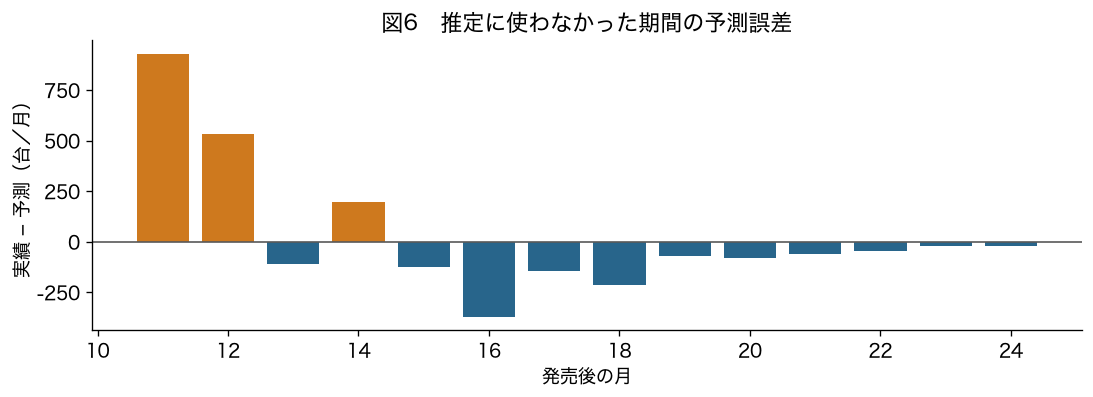

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.20), layout="constrained")
ax.bar(validation_months, validation_residuals,
       color=np.where(validation_residuals >= 0, ORANGE, BLUE))
ax.axhline(0, color="0.35", linewidth=1)
ax.set(title="図6　推定に使わなかった期間の予測誤差",
       xlabel="発売後の月", ylabel="実績 − 予測（台／月）")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
save_svg(fig, "06_validation.svg")

### データが増えると推定値は変わる

図7は、使用するデータを6か月から10か月まで増やした結果である。初期には異なる市場規模でも似た販売曲線になり得るため、$M$が大きく動く。この例で10か月目に設定値へ近づくことは、一般に10か月あれば十分という意味ではない。

[{'使用月数': 6, 'p': '0.0474', 'q': '0.410', 'M': '5.23e+04'},
 {'使用月数': 7, 'p': '0.0211', 'q': '0.303', 'M': '1.22e+05'},
 {'使用月数': 8, 'p': '0.0219', 'q': '0.307', 'M': '1.17e+05'},
 {'使用月数': 9, 'p': '0.0226', 'q': '0.310', 'M': '1.13e+05'},
 {'使用月数': 10, 'p': '0.0255', 'q': '0.334', 'M': '9.85e+04'}]


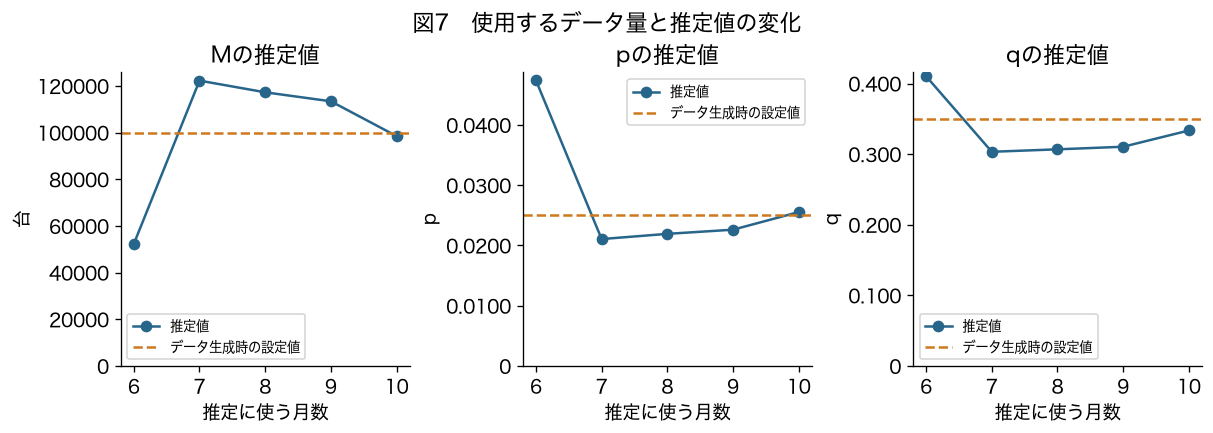

In [19]:
stability = []
for length in range(6, 11):
    y_sub = y[:length]
    floor_sub = float(y_sub.sum())
    starts = [(0.00500, 0.200, floor_sub * 1.50),
              (0.0100, 0.300, floor_sub * 3.00),
              (0.0300, 0.500, floor_sub * 6.00),
              (0.0800, 0.700, floor_sub * 10.0)]
    fit_sub = estimate_bass(periods[:length], y_sub, floor_sub, starts)
    stability.append(fit_sub["popt"])
stability = np.asarray(stability)

pprint([{"使用月数": length, "p": sig3(values[0]), "q": sig3(values[1]),
         "M": sig3(values[2])} for length, values in zip(range(6, 11), stability)],
       sort_dicts=False)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.50), layout="constrained")
for ax, index, name, truth in zip(axes, [2, 0, 1], ["M", "p", "q"],
                                 [M_true, p_true, q_true]):
    ax.plot(range(6, 11), stability[:, index], "o-", color=BLUE, label="推定値")
    ax.axhline(truth, color=ORANGE, linestyle="--", label="データ生成時の設定値")
    ax.set(title=f"{name}の推定値", xlabel="推定に使う月数", ylabel="台" if name == "M" else name)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8)
fig.suptitle("図7　使用するデータ量と推定値の変化")
save_svg(fig, "07_stability.svg")

## 結論

この記事では、バスモデルで新製品の普及を表し、販売のピークと潜在市場規模を推定する手順を紹介した。

この例はモデルの仮定に沿った模擬データであり、実務で同じ精度を保証するものではない。予測は在庫、調達期間、供給能力と照らして使い、実績が増えるたびに更新する。私は、1つの推定値よりも、前月から見積もりがどれだけ変わったかを確認したい。

本書第3章では、データ収集上の注意、係数の解釈、予測を生産・在庫・販促の判断へ使う際の考え方も説明している。詳細な実装は[本書のサポートページ](https://github.com/gihyo-book/marketing_science_book/blob/main/03/03_main.ipynb)で確認できる。

参考文献：Bass, F. M. (1969), “A New Product Growth for Model Consumer Durables”, *Management Science*。本記事の元資料は`doc/03/03_main.tex`および`doc/03/03_main.ipynb`である。